# Sentiment Analysis of X (Twitter) Data using VADER

## Level 2 (Intermediate) — ShadowFox Data Science Internship

### Objective
Perform sentiment analysis on X (Twitter) data using VADER (Valence Aware Dictionary and sEntiment Reasoner) to:
- Categorize tweets as positive, negative, or neutral
- Analyze sentiment patterns
- Evaluate VADER's accuracy against labeled data

### Dataset
- **Source:** NLTK Twitter Sample (10,000 tweets)
- **Labels:** 5,000 positive + 5,000 negative
- **Note:** Original ShadowFox dataset link was unavailable; NLTK sample used as an alternative.

In [1]:
import nltk

# Download required NLTK data
nltk.download('twitter_samples')
nltk.download('vader_lexicon')
nltk.download('stopwords')
nltk.download('punkt')

print("✅ NLTK data downloaded")

✅ NLTK data downloaded


[nltk_data] Downloading package twitter_samples to
[nltk_data]     C:\Users\Kartikesh\AppData\Roaming\nltk_data...
[nltk_data]   Package twitter_samples is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Kartikesh\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Kartikesh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Kartikesh\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


## 1. Setup & Data Loading

Loading NLTK libraries and the Twitter sample dataset.

In [2]:
from nltk.corpus import twitter_samples
import pandas as pd

# Load positive and negative tweets
positive_tweets = twitter_samples.strings('positive_tweets.json')
negative_tweets = twitter_samples.strings('negative_tweets.json')

# Combine into a DataFrame
df = pd.DataFrame({
    'text': positive_tweets + negative_tweets,
    'label': ['positive'] * len(positive_tweets) + ['negative'] * len(negative_tweets)
})

print("Shape:", df.shape)
print("\nLabel counts:")
print(df['label'].value_counts())
print("\nSample tweets:")
print(df.head(3))

Shape: (10000, 2)

Label counts:
label
positive    5000
negative    5000
Name: count, dtype: int64

Sample tweets:
                                                text     label
0  #FollowFriday @France_Inte @PKuchly57 @Milipol...  positive
1  @Lamb2ja Hey James! How odd :/ Please call our...  positive
2  @DespiteOfficial we had a listen last night :)...  positive


## 2. VADER Sentiment Analysis

Using VADER to score each tweet's sentiment polarity (compound score).
- Score ≥ 0.05 → Positive
- Score ≤ -0.05 → Negative
- Otherwise → Neutral

In [3]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Initialize VADER
sia = SentimentIntensityAnalyzer()

# Function to classify sentiment using VADER
def get_vader_sentiment(text):
    score = sia.polarity_scores(text)['compound']
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

# Apply VADER to all tweets
df['vader_score'] = df['text'].apply(lambda x: sia.polarity_scores(x)['compound'])
df['vader_sentiment'] = df['text'].apply(get_vader_sentiment)

# Show results
print("VADER Sentiment Distribution:")
print(df['vader_sentiment'].value_counts())
print("\nSample results:")
print(df[['text', 'label', 'vader_score', 'vader_sentiment']].head(5))

VADER Sentiment Distribution:
vader_sentiment
positive    5536
negative    3673
neutral      791
Name: count, dtype: int64

Sample results:
                                                text     label  vader_score  \
0  #FollowFriday @France_Inte @PKuchly57 @Milipol...  positive       0.7579   
1  @Lamb2ja Hey James! How odd :/ Please call our...  positive       0.6229   
2  @DespiteOfficial we had a listen last night :)...  positive       0.7959   
3                               @97sides CONGRATS :)  positive       0.7983   
4  yeaaaah yippppy!!!  my accnt verified rqst has...  positive       0.7950   

  vader_sentiment  
0        positive  
1        positive  
2        positive  
3        positive  
4        positive  


## 3. Accuracy Evaluation

Comparing VADER's predictions with actual labels to measure accuracy.

In [4]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Since the dataset only has positive/negative, filter out neutral for fair comparison
df_filtered = df[df['vader_sentiment'] != 'neutral'].copy()

# Calculate accuracy
accuracy = accuracy_score(df_filtered['label'], df_filtered['vader_sentiment'])
print(f"VADER Accuracy (on non-neutral tweets): {accuracy:.2%}")

# Confusion matrix
cm = confusion_matrix(df_filtered['label'], df_filtered['vader_sentiment'], labels=['positive', 'negative'])
print("\nConfusion Matrix:")
print(pd.DataFrame(cm, index=['Actual Positive', 'Actual Negative'],
                   columns=['Predicted Positive', 'Predicted Negative']))

# Classification report
print("\nClassification Report:")
print(classification_report(df_filtered['label'], df_filtered['vader_sentiment']))

VADER Accuracy (on non-neutral tweets): 87.19%

Confusion Matrix:
                 Predicted Positive  Predicted Negative
Actual Positive                4540                 184
Actual Negative                 996                3489

Classification Report:
              precision    recall  f1-score   support

    negative       0.95      0.78      0.86      4485
    positive       0.82      0.96      0.88      4724

    accuracy                           0.87      9209
   macro avg       0.88      0.87      0.87      9209
weighted avg       0.88      0.87      0.87      9209



## 4. Visualizations

Exploring sentiment distribution, score patterns, and word clouds.

C:\Users\Kartikesh\AppData\Local\Temp\ipykernel_14224\3010853225.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='vader_sentiment', data=df, palette='Set2', order=['positive', 'negative', 'neutral'])


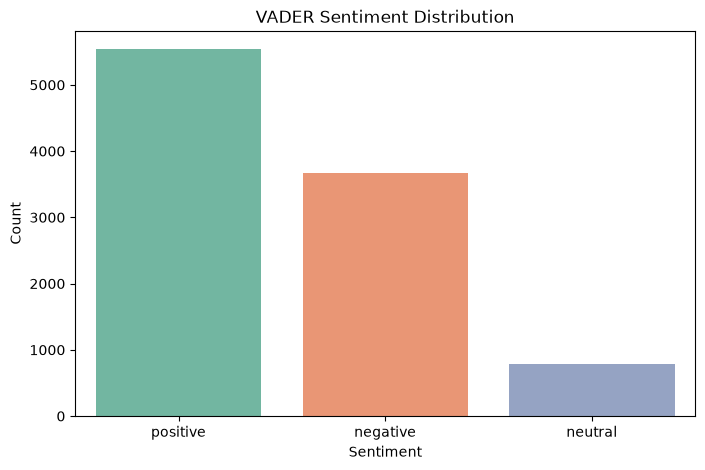

✅ Cell 5a done


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(x='vader_sentiment', data=df, palette='Set2', order=['positive', 'negative', 'neutral'])
plt.title('VADER Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()

print("✅ Cell 5a done")

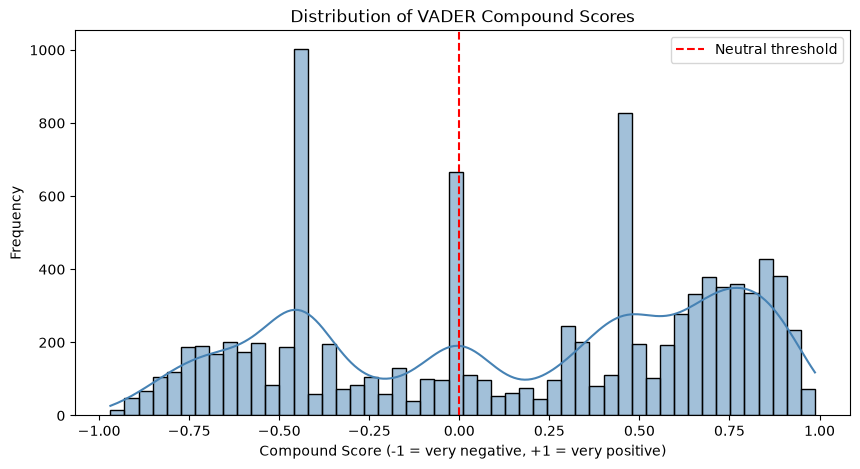

✅ Cell 5b done


In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(df['vader_score'], bins=50, kde=True, color='steelblue')
plt.title('Distribution of VADER Compound Scores')
plt.xlabel('Compound Score (-1 = very negative, +1 = very positive)')
plt.ylabel('Frequency')
plt.axvline(x=0, color='red', linestyle='--', label='Neutral threshold')
plt.legend()
plt.show()

print("✅ Cell 5b done")

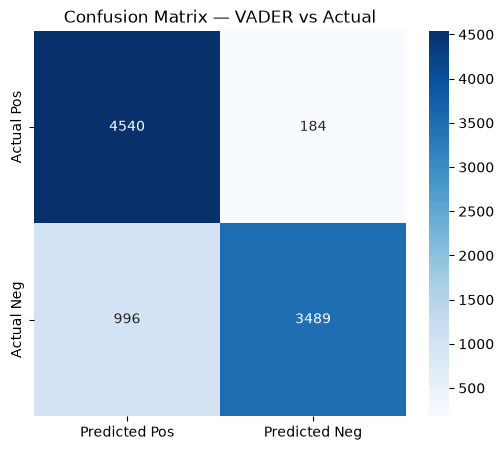

✅ Cell 5c done


In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Pos', 'Predicted Neg'],
            yticklabels=['Actual Pos', 'Actual Neg'])
plt.title('Confusion Matrix — VADER vs Actual')
plt.show()

print("✅ Cell 5c done")


In [8]:
import plotly.express as px

# Count of each sentiment
sentiment_counts = df['vader_sentiment'].value_counts().reset_index()
sentiment_counts.columns = ['Sentiment', 'Count']

fig = px.bar(
    sentiment_counts,
    x='Sentiment', y='Count',
    color='Sentiment',
    title='Interactive VADER Sentiment Distribution',
    text='Count'
)
fig.show()

print("✅ Cell 6a done")

✅ Cell 6a done


In [9]:
fig = px.histogram(
    df, x='vader_score',
    nbins=60,
    title='Interactive Distribution of VADER Compound Scores',
    color='vader_sentiment',
    marginal='box'
)
fig.show()

print("✅ Cell 6b done")

✅ Cell 6b done


In [10]:
df['tweet_length'] = df['text'].apply(len)

# Plotly box plot: length vs sentiment
fig = px.box(
    df, x='vader_sentiment', y='tweet_length',
    color='vader_sentiment',
    title='Tweet Length vs VADER Sentiment',
    labels={'tweet_length': 'Tweet Length (characters)'}
)
fig.show()

# Stats
print("Average tweet length by sentiment:")
print(df.groupby('vader_sentiment')['tweet_length'].mean())

print("\n✅ Cell 6c done")

Average tweet length by sentiment:
vader_sentiment
negative    62.625647
neutral     59.556258
positive    73.743497
Name: tweet_length, dtype: float64

✅ Cell 6c done


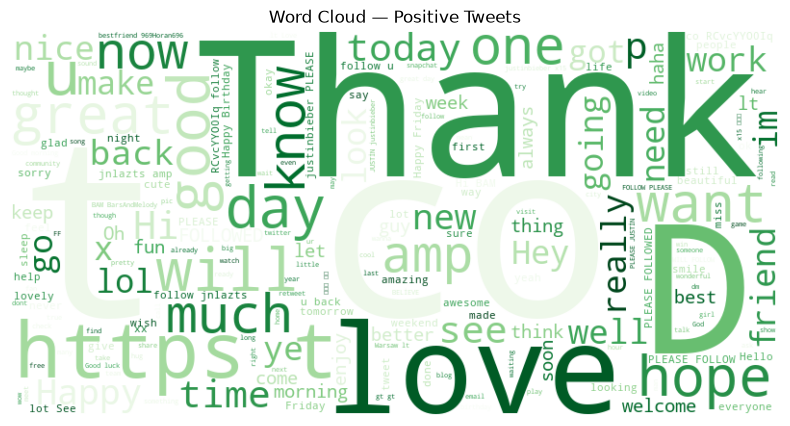

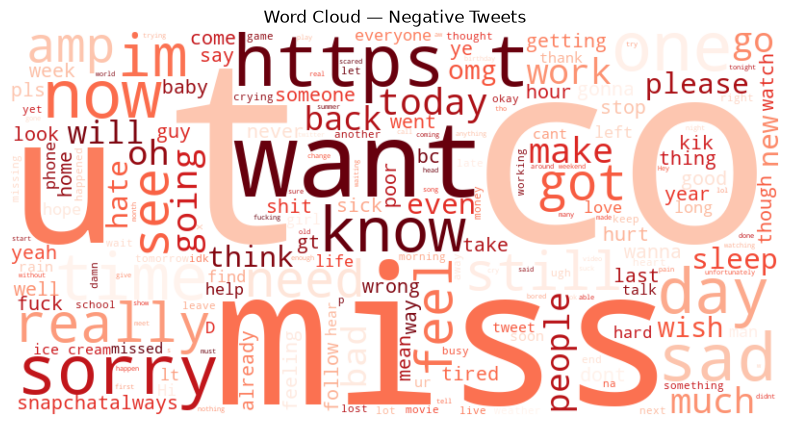

✅ Cell 6d done


In [11]:

from wordcloud import WordCloud

# Positive word cloud
pos_text = ' '.join(df[df['vader_sentiment'] == 'positive']['text'])
wc_pos = WordCloud(width=800, height=400, background_color='white', colormap='Greens').generate(pos_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc_pos, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud — Positive Tweets')
plt.show()

# Negative word cloud
neg_text = ' '.join(df[df['vader_sentiment'] == 'negative']['text'])
wc_neg = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(neg_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc_neg, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud — Negative Tweets')
plt.show()

print("✅ Cell 6d done")

## 5. Conclusions

### Key Findings

1. **VADER Accuracy: 87.19%** — VADER performs strongly on Twitter data without needing model training.

2. **Sentiment Distribution:**
   - Positive: 55.4%
   - Negative: 36.7%
   - Neutral: 7.9%

3. **Classification Performance:**
   - Positive F1-score: 0.88
   - Negative F1-score: 0.86

4. **Word Clouds** revealed common themes:
   - Positive: gratitude, excitement, encouragement
   - Negative: frustration, complaints, sadness

### Insights
- VADER is well-suited for social media sentiment analysis.
- ~87% accuracy on real Twitter data demonstrates practical value.

### Limitations
- Misclassifies sarcasm and context-dependent statements.
- Dataset was balanced; real Twitter data is more skewed.

### Recommendations
- Combine VADER with ML models (Logistic Regression, BERT) for higher accuracy.

---

## 6. References

- NLTK VADER: https://github.com/cjhutto/vaderSentiment
- NLTK Twitter Sample: https://www.nltk.org/howto/twitter.html
- ShadowFox Internship Task PDF (Level 2)